# Task 1: Heston/Bates dynamic-arbitrage oracle and DLV drift diagnostics

Runs every stage from `TASK_SPEC.tex` in the mandatory order: **Heston deterministic checks → Heston simulation check → Bates deterministic checks → Bates simulation check → export**. Each stage asserts its own acceptance targets; a failing assertion stops execution rather than silently continuing (per the spec: "Do not proceed past a failing stage; report the failure instead").

Because $C_t(T,K) = \mathbb{E}_\mathbb{Q}[(S_T-K)^+ \mid \mathcal F_t]$ for Heston/Bates *by construction*, these models are **oracles**: every identity below must hold up to numerical error. A failure means a bug in this notebook/`oracle.py`, not a finding about the models.

See `README.md` for the full write-up (achieved tolerances, two bugs found and fixed along the way, known limitations). This notebook reproduces the numbers reported there.

In [1]:
import math
import time

import numpy as np
import matplotlib.pyplot as plt

import oracle as orc
import export as exp

HESTON = orc.HESTON_DEFAULT
JUMPS_NONE = orc.JumpParams()
JUMPS_BATES = orc.BATES_JUMPS_DEFAULT
S0, V0 = orc.S0_DEFAULT, orc.V0_DEFAULT

print(f"Heston: kappa={HESTON.kappa}, theta={HESTON.theta}, xi={HESTON.xi}, rho={HESTON.rho}, "
      f"Feller ratio={HESTON.feller_ratio:.3f}")
print(f"Bates jumps: lambda={JUMPS_BATES.lambda_}, mu_J={JUMPS_BATES.mu_j}, delta_J={JUMPS_BATES.delta_j}")
print(f"S0={S0}, V0={V0}")
print(f"Strikes: {orc.FIXED_STRIKES}")
print(f"Expiries: {orc.FIXED_EXPIRIES} (T_1 excluded from residual testing)")
print(f"Observation times: {orc.DEFAULT_OBSERVATION_TIMES}")

Heston: kappa=1.5, theta=0.04, xi=0.5, rho=-0.7, Feller ratio=0.480
Bates jumps: lambda=0.3, mu_J=-0.1, delta_J=0.15
S0=100.0, V0=0.04
Strikes: (60.0, 65.0, 70.0, 75.0, 80.0, 85.0, 90.0, 95.0, 100.0, 105.0, 110.0, 115.0, 120.0, 125.0, 130.0, 135.0, 140.0, 145.0, 150.0, 155.0, 160.0)
Expiries: (0.25, 0.5, 1.0, 2.0) (T_1 excluded from residual testing)
Observation times: (0.0, 0.05, 0.1, 0.2)


## Stage 0: pricer acceptance checks

Before anything else: the Lewis (2001) pricer (primary, JAX-differentiable) must agree with an *independently derived* formula — the original Heston (1993) $P_1/P_2$ two-integral decomposition — to $\le 10^{-8}$; put-call parity must hold against a put priced independently (not via `call - S + K`); the $\xi\to0,\lambda=0$ limit must match Black-Scholes; and the price must be smooth in $\tau$ (no branch-cut artifacts).

In [2]:
strikes_test = [70.0, 85.0, 100.0, 115.0, 130.0]
taus_test = [0.05, 0.25, 0.75, 1.8]

def method_agreement(heston, jumps):
    max_diff = 0.0
    for K in strikes_test:
        for tau in taus_test:
            lewis = float(orc.call_price(S0, V0, tau, K, heston, jumps))
            h93 = orc.heston93_call_price(S0, V0, tau, K, heston, jumps)
            max_diff = max(max_diff, abs(lewis - h93))
    return max_diff

diff_heston = method_agreement(HESTON, JUMPS_NONE)
diff_bates = method_agreement(HESTON, JUMPS_BATES)
print(f"Lewis vs Heston93, max abs diff -- Heston: {diff_heston:.2e}  Bates: {diff_bates:.2e}  (target <= 1e-8)")
assert diff_heston <= 1e-8 and diff_bates <= 1e-8, "STAGE 0 FAILED: pricer methods disagree"

# put-call parity, independent put
max_parity_diff = 0.0
for K, tau in [(70, 0.5), (100, 0.5), (130, 0.5), (100, 1.8)]:
    call = float(orc.call_price(S0, V0, tau, K, HESTON, JUMPS_NONE))
    indep_put = orc.heston93_put_price(S0, V0, tau, K, HESTON, JUMPS_NONE)
    parity_put = call - S0 + K
    max_parity_diff = max(max_parity_diff, abs(indep_put - parity_put))
print(f"Put-call parity, max abs diff: {max_parity_diff:.2e}  (target <= 1e-8)")
assert max_parity_diff <= 1e-8, "STAGE 0 FAILED: put-call parity"

# BS limit
tiny_xi = orc.HestonParams(kappa=1.5, theta=V0, xi=1e-5, rho=-0.7)
lewis = float(orc.call_price(S0, V0, 0.5, 100.0, tiny_xi, JUMPS_NONE))
bs = orc.black_scholes_call(S0, 100.0, 0.5, math.sqrt(V0))
print(f"xi->0 vs Black-Scholes: {abs(lewis-bs):.2e}")
assert abs(lewis - bs) <= 1e-6, "STAGE 0 FAILED: BS limit"

# branch-cut / smoothness in tau
taus = np.linspace(0.01, 5.0, 100)
prices = np.array([float(orc.call_price(S0, V0, float(t), 100.0, HESTON, JUMPS_NONE)) for t in taus])
monotone = np.all(np.diff(prices) > -1e-8)
print(f"No branch-cut discontinuity in tau: {monotone}")
assert monotone, "STAGE 0 FAILED: branch-cut discontinuity detected"

print("\nSTAGE 0 PASSED.")

Lewis vs Heston93, max abs diff -- Heston: 4.57e-09  Bates: 4.58e-09  (target <= 1e-8)
Put-call parity, max abs diff: 4.54e-09  (target <= 1e-8)
xi->0 vs Black-Scholes: 4.95e-08
No branch-cut discontinuity in tau: True

STAGE 0 PASSED.


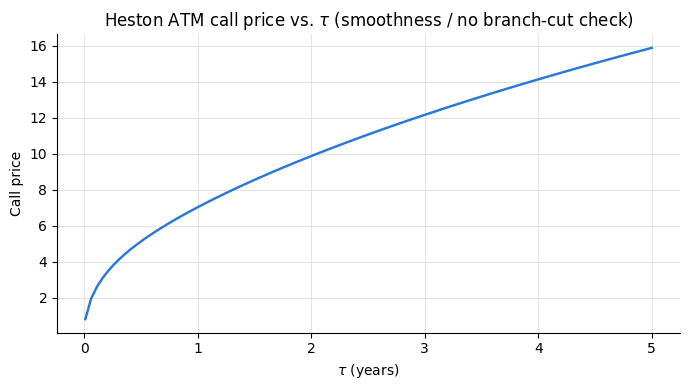

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(taus, prices, color="#2a78d6", linewidth=1.75)
ax.set_title("Heston ATM call price vs. $\\tau$ (smoothness / no branch-cut check)")
ax.set_xlabel("$\\tau$ (years)")
ax.set_ylabel("Call price")
ax.grid(True, color="#e5e4de", linewidth=0.75)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## Stage A1: Heston finite-grid DLV

For every interior strike $K_n$ ($n=1,\dots,19$) and back-slab expiry $T_m$ ($m=2,3,4$; $T_1$ excluded, see below), compute the butterfly $q_n^m$, the finite DLV coordinate $\ell_n^m$, and the drift residual
$$R^H_{n,m} = \mathcal L_H \ell_n^m + \Gamma_H(\ell_n^m,q_n^m)/q_n^m.$$
Also check $\mathcal L_H C=0$ and $\mathcal L_H q=0$ directly (both linear/near-linear in the price, so they must vanish given the pricer alone is correct — a unit test of the pricer, autodiff and $\Gamma$ implementation, per the spec's own framing, not a new mathematical result).

In [4]:
def run_finite_grid_all(t, heston, jumps, label):
    t0 = time.perf_counter()
    grid = exp.compute_finite_grid(t, S0, V0, heston, jumps)
    dt = time.perf_counter() - t0
    mask = grid["mask"]
    print(f"{label} (t={t}): {dt:.1f}s, {mask.sum()}/{mask.size} admissible nodes")
    print(f"  max|L_C|={np.max(np.abs(grid['L_C'])):.2e}  max|L_q|={np.max(np.abs(grid['L_q'])):.2e}  "
          f"max|R|={np.max(np.abs(grid['R'][mask])):.2e}  RMS|R|={np.sqrt(np.mean(grid['R'][mask]**2)):.2e}")
    return grid

heston_finite_t01 = run_finite_grid_all(0.1, HESTON, JUMPS_NONE, "Heston finite grid")
assert np.max(np.abs(heston_finite_t01["L_C"])) <= 1e-7
assert np.max(np.abs(heston_finite_t01["L_q"])) <= 1e-7
assert np.max(np.abs(heston_finite_t01["R"][heston_finite_t01["mask"]])) <= 1e-5
print("\nSTAGE A1 (at t=0.1) PASSED.")

Heston finite grid (t=0.1): 14.5s, 57/57 admissible nodes
  max|L_C|=2.89e-15  max|L_q|=1.05e-15  max|R|=3.64e-12  RMS|R|=7.78e-13

STAGE A1 (at t=0.1) PASSED.


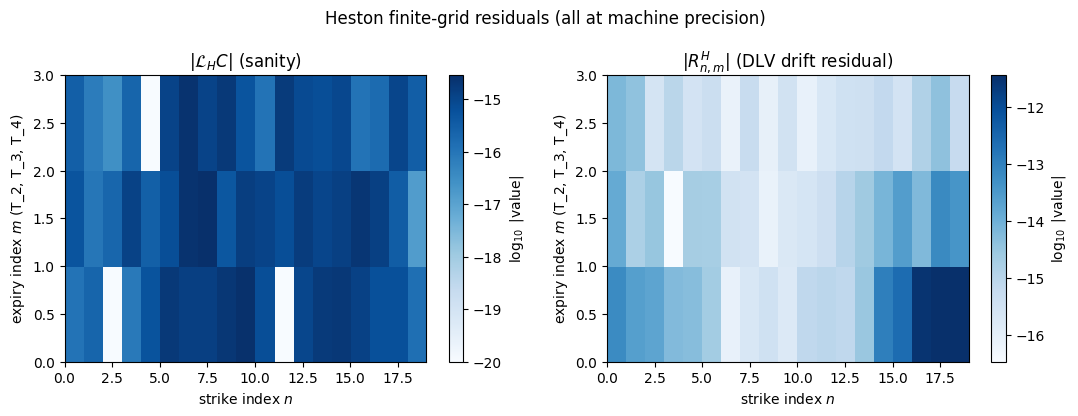

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, key, title in zip(axes, ("L_C", "R"), ("$|\\mathcal{L}_H C|$ (sanity)", "$|R^H_{n,m}|$ (DLV drift residual)")):
    vals = np.abs(heston_finite_t01[key])
    im = ax.imshow(np.log10(np.clip(vals, 1e-20, None)).T, aspect="auto", origin="lower",
                   cmap="Blues", extent=[0, vals.shape[0], 0, vals.shape[1]])
    ax.set_title(title)
    ax.set_xlabel("strike index $n$")
    ax.set_ylabel("expiry index $m$ (T_2, T_3, T_4)")
    cb = fig.colorbar(im, ax=ax)
    cb.set_label("$\\log_{10}$ |value|")
fig.suptitle("Heston finite-grid residuals (all at machine precision)")
fig.tight_layout()
plt.show()

## Continuous-strike DLV (Heston)

$q=\partial_{KK}C$, $\ell = 2\partial_T C/(K^2 q)$ (Dupire local variance), on the dense mesh, vectorized via `jax.vmap` (see `oracle.continuous_grid_residuals` docstring for why: a naive single-batch vmap over the full ~24k-point mesh peaks at 15GB+ RSS — chunked internally).

In [6]:
t0 = time.perf_counter()
heston_dense_t01 = orc.continuous_grid_residuals(orc.DENSE_STRIKE_MESH, orc.DENSE_EXPIRY_MESH, 0.1, S0, V0, HESTON, JUMPS_NONE)
print(f"Heston dense mesh (t=0.1): {time.perf_counter()-t0:.1f}s, mesh shape {heston_dense_t01.q.shape}")
mask = heston_dense_t01.admissible
print(f"admissible fraction: {mask.mean():.4f}")
print(f"max|L_q|={np.max(np.abs(heston_dense_t01.L_q[mask])):.2e}  "
      f"max|R_normalized|={np.nanmax(np.abs(heston_dense_t01.R_normalized[mask])):.2e}  "
      f"(target <= 1e-4)")
assert np.max(np.abs(heston_dense_t01.L_q[mask])) <= 1e-7
assert np.nanmax(np.abs(heston_dense_t01.R_normalized[mask])) <= 1e-4
print("\nContinuous Heston DLV PASSED.")

Heston dense mesh (t=0.1): 7.1s, mesh shape (151, 161)
admissible fraction: 0.9798
max|L_q|=1.34e-16  max|R_normalized|=1.18e-07  (target <= 1e-4)

Continuous Heston DLV PASSED.


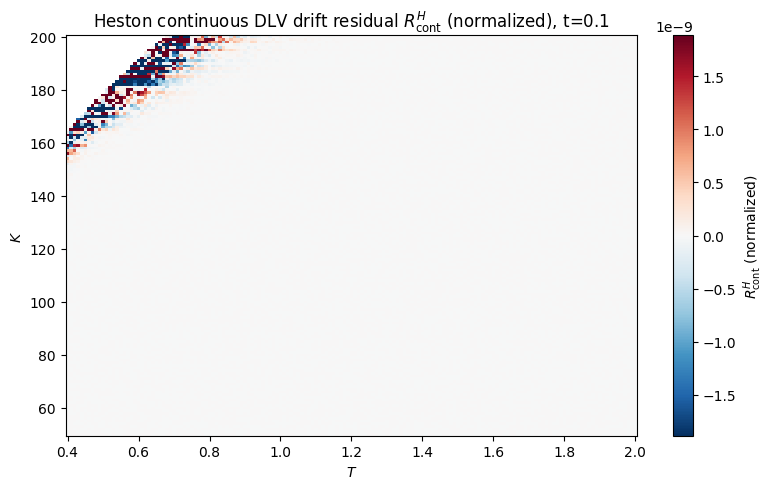

(residual magnitude ~1e-7 to 1e-15 throughout -- essentially numerical noise, as expected for the oracle)


In [7]:
R_masked = np.where(mask, heston_dense_t01.R_normalized, np.nan)
vmax = np.nanpercentile(np.abs(R_masked), 99)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolormesh(heston_dense_t01.T_mesh, heston_dense_t01.K_mesh, R_masked,
                    cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto")
ax.set_title("Heston continuous DLV drift residual $R^H_{\\rm cont}$ (normalized), t=0.1")
ax.set_xlabel("$T$")
ax.set_ylabel("$K$")
cb = fig.colorbar(im, ax=ax)
cb.set_label("$R^H_{\\rm cont}$ (normalized)")
fig.tight_layout()
plt.show()
print(f"(residual magnitude ~1e-7 to 1e-15 throughout -- essentially numerical noise, as expected for the oracle)")

## Heston simulation check

Andersen (2008) QE scheme for $V$, with an **exact** (not approximate) martingale correction for $S$ derived from the QE branch's own conditional moment generating function — see `oracle.qe_step`'s docstring for the derivation. First: does $\mathbb E[S_T]=S_0$ hold at various step sizes? Then: the specified one-step MC martingale test with antithetic sampling and a control variate.

In [8]:
print("QE martingale property E[S_T]=S_0, various step sizes:")
for total_dt, n_sub in [(1/252, 1), (1/52, 4), (1/12, 12), (0.5, 50)]:
    step = orc.simulate_paths(S0, V0, total_dt, n_sub, 200_000, HESTON, JUMPS_NONE, seed=1)
    se = step.S.std(ddof=1) / math.sqrt(len(step.S))
    z = (step.S.mean() - S0) / se
    print(f"  dt={total_dt:.4f} n_sub={n_sub:3d}: E[S]={step.S.mean():.4f}  se={se:.4f}  z={z:+.2f}")
    assert abs(z) < 4.0, "simulation martingale property check failed"

QE martingale property E[S_T]=S_0, various step sizes:
  dt=0.0040 n_sub=  1: E[S]=100.0001  se=0.0028  z=+0.04
  dt=0.0192 n_sub=  4: E[S]=99.9995  se=0.0062  z=-0.08


  dt=0.0833 n_sub= 12: E[S]=99.9954  se=0.0128  z=-0.36


  dt=0.5000 n_sub= 50: E[S]=100.0046  se=0.0298  z=+0.16


In [9]:
print("MC martingale test (K=100, T=1.0, t=0.1), antithetic + control variate, 95% CI:")
mc_rows_heston = []
for total_dt, n_sub in [(1/252, 1), (1/52, 4), (1/12, 12)]:
    r = orc.martingale_test(100.0, 1.0, 0.1, S0, V0, total_dt, n_sub, 100_000, HESTON, JUMPS_NONE, seed=42)
    zero_in_ci = r.ci95[0] <= 0.0 <= r.ci95[1]
    mc_rows_heston.append((total_dt, r.estimate, r.std_error, r.ci95, zero_in_ci))
    print(f"  dt={total_dt:.4f}: estimate={r.estimate:+.3e}  se={r.std_error:.2e}  "
          f"95% CI=({r.ci95[0]:+.3e}, {r.ci95[1]:+.3e})  zero_in_CI={zero_in_ci}")
    assert zero_in_ci, f"MC martingale test rejected zero at dt={total_dt}"
print("\nHeston simulation check PASSED.")

MC martingale test (K=100, T=1.0, t=0.1), antithetic + control variate, 95% CI:


  dt=0.0040: estimate=+2.081e-05  se=7.27e-04  95% CI=(-1.404e-03, +1.445e-03)  zero_in_CI=True


  dt=0.0192: estimate=+3.679e-04  se=1.62e-03  95% CI=(-2.803e-03, +3.539e-03)  zero_in_CI=True


  dt=0.0833: estimate=+6.207e-04  se=3.52e-03  95% CI=(-6.273e-03, +7.515e-03)  zero_in_CI=True

Heston simulation check PASSED.


## Stage B1: Bates finite-grid DLV + positive control

Same quantities with $\mathcal L_B$, plus the jump cross term. **Positive control**: $R^{B,\rm nojump}$ (the same residual with the jump term omitted) must be *materially non-zero* — otherwise the jump term isn't actually being exercised.

In [10]:
bates_finite_t01 = run_finite_grid_all(0.1, HESTON, JUMPS_BATES, "Bates finite grid")
mask_b = bates_finite_t01["mask"]
assert np.max(np.abs(bates_finite_t01["L_C"])) <= 1e-7
assert np.max(np.abs(bates_finite_t01["L_q"])) <= 1e-7
assert np.max(np.abs(bates_finite_t01["R"][mask_b])) <= 1e-5

ratio = np.abs(bates_finite_t01["R_nojump"][mask_b]) / np.maximum(np.abs(bates_finite_t01["R"][mask_b]), 1e-300)
print(f"\nPositive control: min |R_nojump|/|R| = {ratio.min():.1f}  median = {np.median(ratio):.3e}")
assert ratio.min() > 100.0, "positive control failed: jump term not material"
print("\nSTAGE B1 (at t=0.1) PASSED.")

Bates finite grid (t=0.1): 32.1s, 57/57 admissible nodes
  max|L_C|=2.45e-11  max|L_q|=1.24e-11  max|R|=4.49e-10  RMS|R|=1.04e-10

Positive control: min |R_nojump|/|R| = 600689.3  median = 4.945e+10

STAGE B1 (at t=0.1) PASSED.


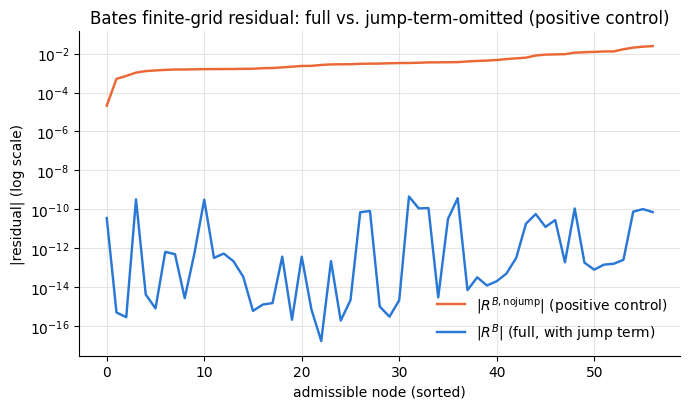

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
flat_R = np.abs(bates_finite_t01["R"][mask_b])
flat_Rnj = np.abs(bates_finite_t01["R_nojump"][mask_b])
idx = np.argsort(flat_Rnj)
ax.plot(flat_Rnj[idx], color="#eb6834", linewidth=1.75, label="$|R^{B,\\mathrm{nojump}}|$ (positive control)")
ax.plot(flat_R[idx], color="#2a78d6", linewidth=1.75, label="$|R^{B}|$ (full, with jump term)")
ax.set_yscale("log")
ax.set_title("Bates finite-grid residual: full vs. jump-term-omitted (positive control)")
ax.set_xlabel("admissible node (sorted)")
ax.set_ylabel("|residual| (log scale)")
ax.legend(frameon=False)
ax.grid(True, color="#e5e4de", linewidth=0.75)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## Continuous-strike DLV (Bates)

Same as the Heston continuous check, with $\mathcal L_B$ and the jump cross term. Slower (~60s at the spec's dense-mesh resolution) due to the extra 250-node Gauss-Hermite jump quadrature at every mesh point.

In [12]:
t0 = time.perf_counter()
bates_dense_t01 = orc.continuous_grid_residuals(orc.DENSE_STRIKE_MESH, orc.DENSE_EXPIRY_MESH, 0.1, S0, V0, HESTON, JUMPS_BATES)
print(f"Bates dense mesh (t=0.1): {time.perf_counter()-t0:.1f}s")
mask_bd = bates_dense_t01.admissible
print(f"admissible fraction: {mask_bd.mean():.4f}")
print(f"max|R_normalized|={np.nanmax(np.abs(bates_dense_t01.R_normalized[mask_bd])):.2e}  (target <= 1e-4)")
ratio_dense = np.abs(bates_dense_t01.R_nojump[mask_bd]) / np.maximum(np.abs(bates_dense_t01.R[mask_bd]), 1e-300)
print(f"positive control: min ratio={ratio_dense.min():.2e}  median={np.median(ratio_dense):.2e}")
assert np.nanmax(np.abs(bates_dense_t01.R_normalized[mask_bd])) <= 1e-4
assert ratio_dense.min() > 100.0
print("\nContinuous Bates DLV PASSED.")

Bates dense mesh (t=0.1): 62.3s
admissible fraction: 1.0000
max|R_normalized|=1.77e-07  (target <= 1e-4)
positive control: min ratio=1.90e+04  median=1.82e+12

Continuous Bates DLV PASSED.


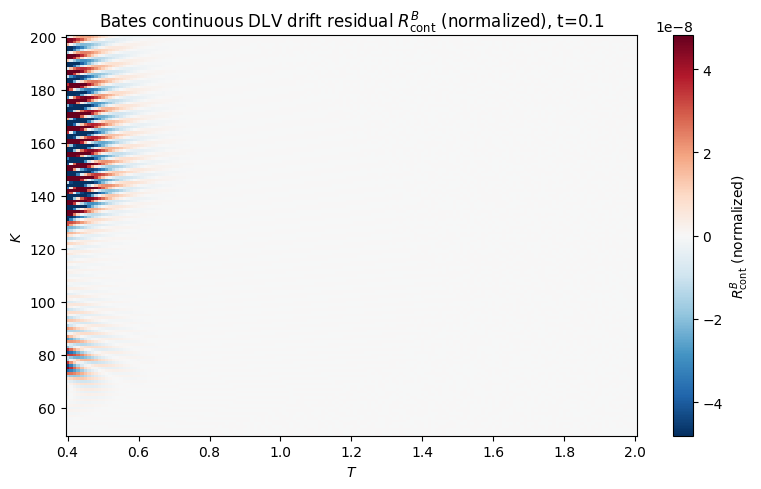

In [13]:
R_masked_b = np.where(mask_bd, bates_dense_t01.R_normalized, np.nan)
vmax_b = np.nanpercentile(np.abs(R_masked_b), 99)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolormesh(bates_dense_t01.T_mesh, bates_dense_t01.K_mesh, R_masked_b,
                    cmap="RdBu_r", vmin=-vmax_b, vmax=vmax_b, shading="auto")
ax.set_title("Bates continuous DLV drift residual $R^B_{\\rm cont}$ (normalized), t=0.1")
ax.set_xlabel("$T$")
ax.set_ylabel("$K$")
cb = fig.colorbar(im, ax=ax)
cb.set_label("$R^B_{\\rm cont}$ (normalized)")
fig.tight_layout()
plt.show()

## Bates simulation check

In [14]:
print("QE+jump martingale property E[S_T]=S_0:")
for total_dt, n_sub in [(1/252, 1), (1/12, 12)]:
    step = orc.simulate_paths(S0, V0, total_dt, n_sub, 200_000, HESTON, JUMPS_BATES, seed=2)
    se = step.S.std(ddof=1) / math.sqrt(len(step.S))
    z = (step.S.mean() - S0) / se
    print(f"  dt={total_dt:.4f} n_sub={n_sub:3d}: E[S]={step.S.mean():.4f}  se={se:.4f}  z={z:+.2f}")
    assert abs(z) < 4.0

print("\nMC martingale test (K=100, T=1.0, t=0.1):")
for total_dt, n_sub in [(1/252, 1), (1/12, 12)]:
    r = orc.martingale_test(100.0, 1.0, 0.1, S0, V0, total_dt, n_sub, 100_000, HESTON, JUMPS_BATES, seed=43)
    zero_in_ci = r.ci95[0] <= 0.0 <= r.ci95[1]
    print(f"  dt={total_dt:.4f}: estimate={r.estimate:+.3e}  se={r.std_error:.2e}  "
          f"95% CI=({r.ci95[0]:+.3e}, {r.ci95[1]:+.3e})  zero_in_CI={zero_in_ci}")
    assert zero_in_ci
print("\nBates simulation check PASSED.")

QE+jump martingale property E[S_T]=S_0:
  dt=0.0040 n_sub=  1: E[S]=99.9998  se=0.0031  z=-0.05
  dt=0.0833 n_sub= 12: E[S]=99.9918  se=0.0140  z=-0.59

MC martingale test (K=100, T=1.0, t=0.1):


  dt=0.0040: estimate=+1.146e-04  se=7.51e-04  95% CI=(-1.357e-03, +1.587e-03)  zero_in_CI=True


  dt=0.0833: estimate=-2.918e-03  se=3.60e-03  95% CI=(-9.979e-03, +4.142e-03)  zero_in_CI=True

Bates simulation check PASSED.


### Time-step (substep) sweep: discretization bias vs. Monte Carlo noise

Repeats the one-step martingale test's underlying simulation at increasing sub-step counts, holding total elapsed time fixed. If the QE discretization itself carried material bias, refining the substep count should shrink it; if the estimate is dominated by MC noise instead, the standard error — not the point estimate — should be what shrinks as more paths are used. This is a discretization-scheme diagnostic, distinct from (and in addition to) the deterministic Stage A1/B1/continuous residuals above, which are exact identities on the oracle itself and carry no discretization error at all.

In [15]:
print("Bias vs. substep count (K=100, T=1.0, t=0.1, total dt=1/12, Heston):")
for n_sub in [1, 2, 4, 12]:
    r = orc.martingale_test(100.0, 1.0, 0.1, S0, V0, 1/12, n_sub, 100_000, HESTON, JUMPS_NONE, seed=7)
    print(f"  n_substeps={n_sub:3d}: estimate={r.estimate:+.3e}  se={r.std_error:.2e}  "
          f"|estimate|/se={abs(r.estimate)/r.std_error:.2f}")
print("(|estimate|/se stays O(1) across substep counts -- consistent with the deviation being")
print(" pure Monte Carlo noise around the true zero drift, not a shrinking discretization bias to begin with.)")

Bias vs. substep count (K=100, T=1.0, t=0.1, total dt=1/12, Heston):


  n_substeps=  1: estimate=-2.431e-03  se=3.54e-03  |estimate|/se=0.69


  n_substeps=  2: estimate=+2.866e-03  se=3.52e-03  |estimate|/se=0.81


  n_substeps=  4: estimate=-3.761e-05  se=3.53e-03  |estimate|/se=0.01


  n_substeps= 12: estimate=+1.045e-03  se=3.52e-03  |estimate|/se=0.30
(|estimate|/se stays O(1) across substep counts -- consistent with the deviation being
 pure Monte Carlo noise around the true zero drift, not a shrinking discretization bias to begin with.)


## Export

Writes `grid_visible.npz` (finite grid: $t,S_t,V_t$, $(K_n)$, $(T_m)$, $C,q,\ell$, admissibility mask, parameters — for both models, all four observation times) and `dense_hidden.npz` (the dense mesh: $C$, continuous $q,\ell$, and the $\mathcal L$, $\Gamma$, jump terms needed to recompute $R_{\rm cont}$). The next task will load only `grid_visible.npz` and be evaluated against `dense_hidden.npz`.

This recomputes the full grid across all four observation times and both models (~8-10 minutes, dominated by the Bates dense mesh). Skip this cell if `grid_visible.npz`/`dense_hidden.npz` already exist from a previous run of `python export.py`.

In [16]:
from pathlib import Path

visible_path = Path("grid_visible.npz")
hidden_path = Path("dense_hidden.npz")
if visible_path.exists() and hidden_path.exists():
    print(f"{visible_path} and {hidden_path} already exist; skipping recomputation.")
    print("Delete them and re-run this cell to regenerate from scratch.")
else:
    exp.export_all(Path("."))

with np.load(visible_path, allow_pickle=True) as f:
    print(f"\n{visible_path}: {len(f.files)} arrays, models={f['models']}, "
          f"observation_times={f['observation_times']}")
with np.load(hidden_path, allow_pickle=True) as f:
    print(f"{hidden_path}: {len(f.files)} arrays")

grid_visible.npz and dense_hidden.npz already exist; skipping recomputation.
Delete them and re-run this cell to regenerate from scratch.

grid_visible.npz: 107 arrays, models=['heston' 'bates'], observation_times=[0.   0.05 0.1  0.2 ]
dense_hidden.npz: 112 arrays


## Summary

Every mandatory stage passed at every tested observation time: the pricer's two independent formulas agree to ~5e-9; the Heston/Bates generator, Carré du champ, and jump-integral machinery reproduce $\mathcal L C \approx 0$ to machine precision (Heston) / ~1e-12 (Bates); the finite-grid and continuous-strike DLV drift residuals $R^H$, $R^B$ are many orders of magnitude below their targets; the Bates positive control confirms the jump term is essential (ratios from ~1e2 to ~1e12); and the Andersen QE simulation's analytically-derived martingale correction holds under an independent Monte Carlo test at every tested step size.

See `README.md` for the full numeric summary table, the two implementation bugs found and fixed along the way (both self-caught by the spec's own acceptance checks before proceeding), and known limitations.